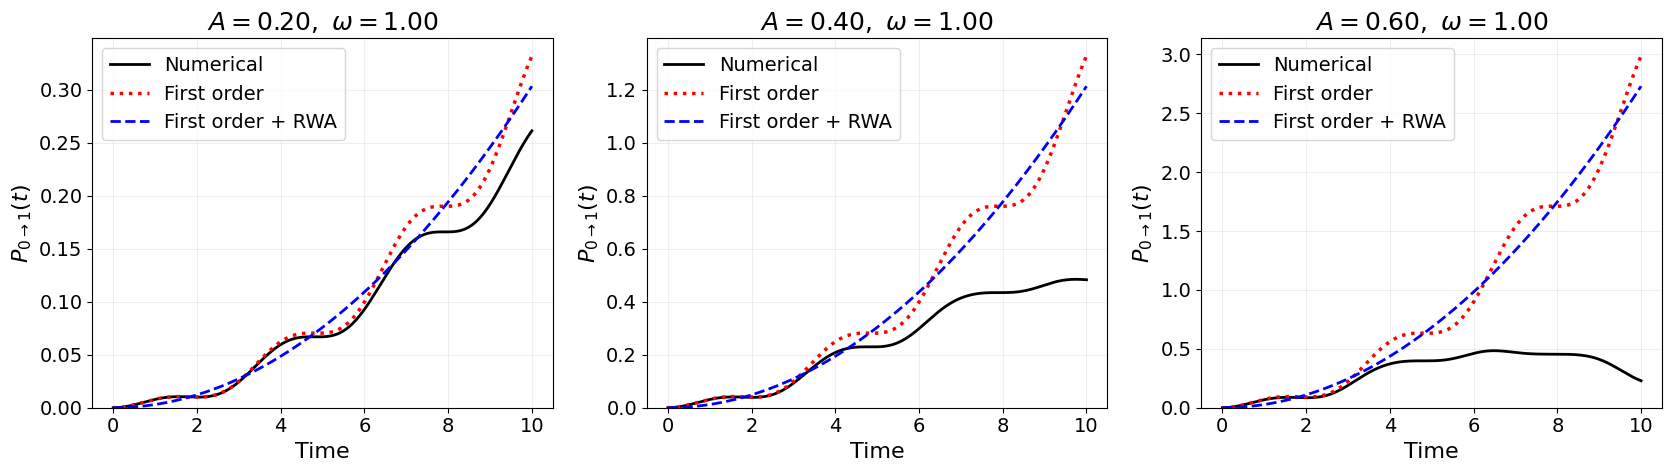

In [4]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# Find harmonic.py in this folder or its parent
folder = Path.cwd()
if not (folder / "harmonic.py").exists():
    folder = folder.parent
sys.path.insert(0, str(folder))

from harmonic import HarmonicOscillator


def simulate(A=0.2, omega=1.0, dt=0.02, n=128, L=12, tmax=20):
    ho = HarmonicOscillator(boundary=(-L, L), n=n)
    energies, basis = ho.eigenstates()

    times = np.linspace(0, tmax, int(np.ceil(tmax / dt)) + 1)
    states = np.empty((len(times), n), dtype=complex)
    states[0] = basis[:, 0]

    for i in range(1, len(times)):
        states[i] = ho.time_evolution(
            [times[i]],
            omega=omega,
            A=A,
            psi0=states[i - 1],
            t0=times[i - 1]
        )

    E0 = (np.abs(states @ basis.conj())**2) @ energies
    return ho.xi(), times, states, E0


# Parameters
n = 128
L = 12
A_values = [0.2, 0.4, 0.6]
omega = 1.0
tmax = 10

# First excited state on the same grid
ho = HarmonicOscillator(boundary=(-L, L), n=n)
_, basis = ho.eigenstates()
phi1 = basis[:, 1]

# Analytical matrix element <1|sin(x)|0>
M10 = np.exp(-0.25) / np.sqrt(2)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, A in zip(axes, A_values):
    _, t, states, _ = simulate(
        A=A, omega=omega,
        n=n, L=L, dt=0.02, tmax=tmax
    )

    P_num = np.abs(states @ phi1.conj())**2

    # First-order theory at omega = 1
    P_full = (A * M10 / 2)**2 * np.abs(
        t + np.exp(1j * t) * np.sin(t)
    )**2

    # First-order theory with RWA
    P_rwa = (A * M10 * t / 2)**2

    ax.plot(t, P_num, "k-", linewidth=2, label="Numerical")
    ax.plot(t, P_full, "r:", linewidth=2.5, label="First order")
    ax.plot(t, P_rwa, "b--", linewidth=2, label="First order + RWA")

    ax.set_title(rf"$A={A:.2f},\ \omega=1.00$")
    ax.set_xlabel("Time")
    ax.set_ylabel(r"$P_{0\to1}(t)$")
    ax.set_ylim(bottom=0)
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()